# High-contrast imaging with `jighcontrast`: finding a planet beside a star

This notebook is a worked example of **angular differential imaging (ADI)** with
**principal-component (KLIP-style) point-spread-function (PSF) subtraction**,
using the [`jighcontrast`](https://github.com/jordan-stone/jighcontrast) package.
Starting from a time series of integral-field-spectrograph (IFS) images of a
bright star, we remove the star's light and search for a much fainter companion
(a planet) hidden in its glare.

We will:

1. Load and look at the raw data.
2. Build a library of reference images and subtract a PSF model with PCA.
3. Rotate ("derotate") and combine the residuals so that a real companion adds up.
4. Collapse the spectral cube into a single broadband detection image.
5. Measure the companion's signal-to-noise.

Images are shown with [`jfits`](https://github.com/jordan-stone/jfits), which
provides interactive pan/zoom and adjustable color scaling inside JupyterLab.

## The data

Each file holds a single **4-dimensional** array with axes
`(time, wavelength, y, x)`:

| axis | length | meaning |
|------|--------|---------|
| time | 90 | successive exposures taken while the sky rotated (this rotation is what ADI exploits) |
| wavelength | 54 | spectral channels of the integral-field spectrograph |
| y, x | 108 x 108 | spatial pixels of each monochromatic image |

The exposures simulate a **coronagraphic** observation: the star sits behind a
mask that suppresses its bright peak. How far the sky had rotated at each
exposure (the *parallactic angle*) is listed in `parallactic_angle_degrees.csv`.

A planet has been injected at a **known** position. This example ships the
**bright** case, `IFScube_seq_adi_coronagraph_pLmag9_sLmag5p3.fits`, with a
planet-to-star flux ratio of roughly `3e-2`. The `pLmag9` in the filename is the
**planet's** magnitude in the observing band (the `sLmag5p3` is the star's, which
is the same across the simulation). Fainter injected planets -- where a detection
becomes marginal or fails outright -- are discussed in the detection-limits
section at the end.

## Setup

Install the packages once:

```bash
pip install "jighcontrast @ git+https://github.com/jordan-stone/jighcontrast" jfits ipympl
```

`ipympl` provides the `widget` matplotlib backend used below for the interactive
figures (pan/zoom and adjustable color scaling). Those live controls only work
in **JupyterLab** -- the classic `jupyter notebook` interface and static viewers
(GitHub, nbviewer) show a non-interactive snapshot instead. Start it with:

```bash
jupyter lab example_adi_reduction.ipynb
```

In [1]:
%matplotlib widget
import warnings

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.ndimage import gaussian_filter

import jfits
from jighcontrast import jPCA, jPhot, nan_rot

# Some output pixels lie outside the optimization ring in every frame; taking a
# median over those all-empty stacks is harmless, so silence that warning.
warnings.filterwarnings("ignore", message="All-NaN slice encountered")
# jfits' log color-scaling evaluates log() on masked/zero pixels; the result is
# handled internally (np.where), so silence the numpy warnings it would print.
warnings.filterwarnings("ignore", message="divide by zero encountered in log")
warnings.filterwarnings("ignore", message="invalid value encountered in log")

## 1. Configuration

Everything you might want to change lives in this cell: which file to reduce, the
instrument properties, the (known) position of the injected planet, and the two
main knobs of the PSF subtraction.

In [2]:
# --- which data set to reduce -------------------------------------------------
DATA_FILE = "IFScube_seq_adi_coronagraph_pLmag9_sLmag5p3.fits"
ANGLES_FILE = "parallactic_angle_degrees.csv"

# --- instrument / observation -------------------------------------------------
PIXEL_SCALE = 20.0                        # milliarcseconds per pixel
WAVELENGTHS = np.linspace(3.1, 3.5, 54)   # micron, one value per spectral channel
TELESCOPE_DIAMETER = 10.0                 # meters (sets the PSF size, lambda / D)

# --- injected planet (known for this simulation) ------------------------------
PLANET_SEPARATION_MAS = 390.0             # separation from the star, milliarcsec
PLANET_POSITION_ANGLE = 217.0             # degrees east of north (CCW from "up")

# --- PSF-subtraction knobs ----------------------------------------------------
N_COMPONENTS = 4     # principal components to remove (more = more aggressive;
                     # too many also subtracts the planet itself)
ANNULUS_WIDTH = 7    # width (pixels) of the ring the subtraction is optimized in,
                     # centered on the planet's separation

## 2. Load the data

The data cube (~430 MB) is too large to store in the git repository, so it is
distributed as a **release asset**. The cell below downloads it into the working
directory the first time you run the notebook; afterwards it uses the local copy.
The small parallactic-angle file ships alongside this notebook in the repository.

In [3]:
import os
import urllib.request

DATA_URL = ("https://github.com/jordan-stone/jighcontrast/releases/download/"
            "example-data/" + DATA_FILE)
if not os.path.exists(DATA_FILE):
    print(f"downloading {DATA_FILE} (~430 MB), one time only ...")
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)
    print("done")

In [4]:
data_cube = fits.getdata(DATA_FILE).astype(float)    # (time, wavelength, y, x)
angles_deg = np.loadtxt(ANGLES_FILE, delimiter=",")  # parallactic angle per exposure

n_exposures, n_channels, ny, nx = data_cube.shape
star_center = ((nx - 1) / 2, (ny - 1) / 2)           # (x, y); the star is at the field center

print(f"data cube : {n_exposures} exposures x {n_channels} wavelengths x {ny} x {nx} pixels")
print(f"sky rotation over the sequence : {angles_deg.max() - angles_deg.min():.1f} degrees")
print(f"star centered at (x, y) = {star_center}")

data cube : 90 exposures x 54 wavelengths x 108 x 108 pixels
sky rotation over the sequence : 108.2 degrees
star centered at (x, y) = (53.5, 53.5)


## 3. Look at the raw data

Collapsing one exposure over all wavelengths shows the coronagraphic stellar PSF
and its **speckles** -- the quasi-static bright blobs that mimic planets and are
the main obstacle to a detection. Use the toolbar to zoom and the sliders beneath
the image to adjust the brightness scaling.

In a single raw frame the planet is far too faint to pick out by eye; it is
buried under the stellar speckles.

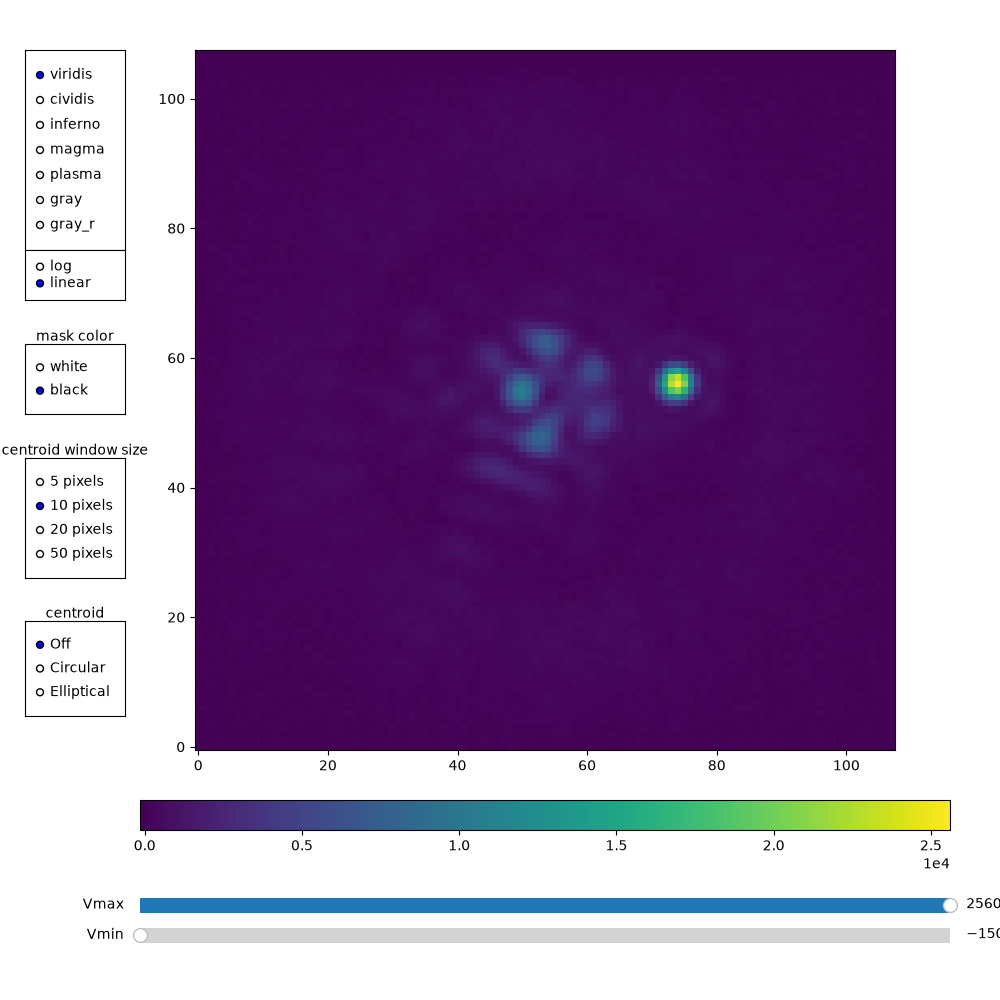

In [5]:
one_exposure = np.median(data_cube[0], axis=0)   # exposure 0, averaged over wavelength
jfits.InteractiveDisplay(one_exposure)

## 4. How the PSF subtraction works

The star's speckle pattern is nearly the same from one exposure to the next,
while a real companion appears to rotate around the star as the sky rotates --
that is what *angular differential imaging* exploits. The recipe:

1. **Reference library.** For each exposure, gather the *other* exposures to model
   the starlight. We keep only exposures where the sky has rotated enough that a
   companion has moved elsewhere; otherwise we would build the planet into the
   model and subtract it from itself (`jPCA.make_adi_library`).
2. **Principal components.** Find the few image patterns (principal components)
   that best describe the reference library's speckles (`jPCA.PCA`) and remove
   the part of the target exposure they explain. Keeping only a handful of
   components models the smooth speckle field without absorbing a compact planet.
3. **Derotate and combine.** Rotate each residual so the sky is aligned in every
   frame (`nan_rot.nan_rot`). Speckle residuals average away, while the companion
   -- now always at the same sky position -- adds up.
4. Repeat per wavelength and combine.

We restrict the subtraction to a narrow **ring** (annulus) at the planet's
separation so the principal components describe the local speckle field where the
planet actually is.

In [6]:
# Distance of every pixel from the star, used both to define the optimization
# ring and to place the planet's known sky position on the pixel grid.
y_grid, x_grid = np.indices((ny, nx))
radius = np.hypot(x_grid - star_center[0], y_grid - star_center[1])

planet_separation_pix = PLANET_SEPARATION_MAS / PIXEL_SCALE
optimization_region = np.abs(radius - planet_separation_pix) <= ANNULUS_WIDTH / 2

# Planet pixel position. Position angle is east of north: counter-clockwise from
# straight up, with east to the left.
pa = np.deg2rad(PLANET_POSITION_ANGLE)
planet_x = star_center[0] - planet_separation_pix * np.sin(pa)
planet_y = star_center[1] + planet_separation_pix * np.cos(pa)

print(f"planet separation : {planet_separation_pix:.1f} px")
print(f"planet pixel (x, y) : ({planet_x:.1f}, {planet_y:.1f})")
print(f"optimization ring : {optimization_region.sum()} pixels")

planet separation : 19.5 px
planet pixel (x, y) : (65.2, 37.9)
optimization ring : 852 pixels


## 5. Reduce one wavelength

The function below carries out steps 1-3 for a single spectral channel and
returns the derotated, combined residual image. We call it for every wavelength.

Two details worth flagging:

- `make_adi_library` measures how far a companion moves using a separation you
  supply, so we pass the planet's separation to protect it from self-subtraction.
- **Derotation sign.** `nan_rot` rotates by the angle you give it in its own fixed
  sense, so the sign that *undoes* the sky rotation is set by that convention, not
  by physics. Here `-angle` is correct. If you swap in a different rotation
  routine, verify the sign by checking that a known off-axis source stacks into a
  point rather than smearing into an arc.

In [7]:
def reduce_one_wavelength(images, angles, region, n_components, ref_separation_pix):
    """PSF-subtract and derotate one wavelength's worth of exposures.

    Parameters
    ----------
    images : ndarray (n_exposures, ny, nx)
        The exposures at a single wavelength.
    angles : ndarray (n_exposures,)
        Parallactic angle of each exposure, in degrees.
    region : boolean ndarray (ny, nx)
        Optimization region: the pixels the PCA model is fit over.
    n_components : int
        Number of principal components to subtract.
    ref_separation_pix : float
        Separation (pixels) at which reference exclusion is evaluated.

    Returns
    -------
    ndarray (ny, nx)
        The exposure-combined, derotated residual image (NaN outside `region`).
    """
    ny, nx = images.shape[1:]
    center = ((nx - 1) / 2, (ny - 1) / 2)

    derotated = []
    for i, angle in enumerate(angles):
        # 1. reference library: the other exposures in which a companion at this
        #    separation has rotated clear of its position in exposure i.
        #    (make_adi_library edits the angle array it receives, so pass a copy.)
        reference_images, _ = jPCA.make_adi_library(
            list(images), angles.copy(),
            rad_in_pix=ref_separation_pix, ref_q=angle, buffer_radius=4.0)
        if len(reference_images) < n_components + 1:
            continue

        # 2. build the principal components and subtract them from this exposure
        pca = jPCA.PCA(reference_images, region)
        residual_pixels = pca(images[i].copy(), n_components)

        residual_image = np.full((ny, nx), np.nan)
        residual_image[region] = residual_pixels

        # 3. derotate so the sky (and any real companion) aligns across frames
        derotated.append(
            nan_rot.nan_rot(residual_image, -angle, center, out_size=(ny, nx)))

    return np.nanmedian(derotated, axis=0)

## 6. Run the reduction

We loop over all wavelengths, building a reduced spectral cube of residual
images. With this narrow ring it takes a few tens of seconds; a wider region or
more exposures would take longer.

The PCA uses the default `method='svd'`, which is more than fast enough for a
single pass over this small annulus. You'll notice `jPCA.PCA` prints a one-time
note below: it detects that our optimization region is strongly *rectangular*
(far more pixels than exposures) and points out that `method='eigh'` --- which
eigendecomposes the smaller covariance instead --- would build each PCA faster.
It isn't worth switching for one reduction like this, but that per-build saving
compounds when you have many more images, run a full **SDI** reduction, or
iterate the whole reduction over many injected sources to map detection limits.
The catch is a little numerical precision (see the closing notes), so `svd`
stays the safe default.

In [8]:
reduced_cube = np.empty((n_channels, ny, nx))
for w in range(n_channels):
    reduced_cube[w] = reduce_one_wavelength(
        data_cube[:, w], angles_deg, optimization_region,
        N_COMPONENTS, planet_separation_pix)
    print(f"\rreduced wavelength {w + 1}/{n_channels}", end="")
print("  done")

jPCA.PCA: strongly rectangular optimization region (70 images x 852 pixels, 12:1). method='eigh' decomposes the smaller 70x70 covariance and skips the larger dimension, so it is usually faster here; over the many PCA builds in an ADI/SDI reduction (and repeated injection-recovery runs) that saving compounds. Trade-off: eigh forms a covariance (Gram) matrix, squaring its condition number and possibly costing a few digits of precision -- keep the default 'svd' if you need maximum numerical stability or push npca deep into the small-eigenvalue tail. (this hint prints once per session)


reduced wavelength 1/54

reduced wavelength 2/54

reduced wavelength 3/54

reduced wavelength 4/54

...

reduced wavelength 50/54

reduced wavelength 51/54

reduced wavelength 52/54

reduced wavelength 53/54

reduced wavelength 54/54  done


## 7. Inspect the reduced spectral cube

`InteractiveDisplayCube` adds a slider to step through wavelength. The star's
residual sits at the center; scan the ring for a compact source that stays put in
wavelength (a real companion) versus speckle residuals that come and go.

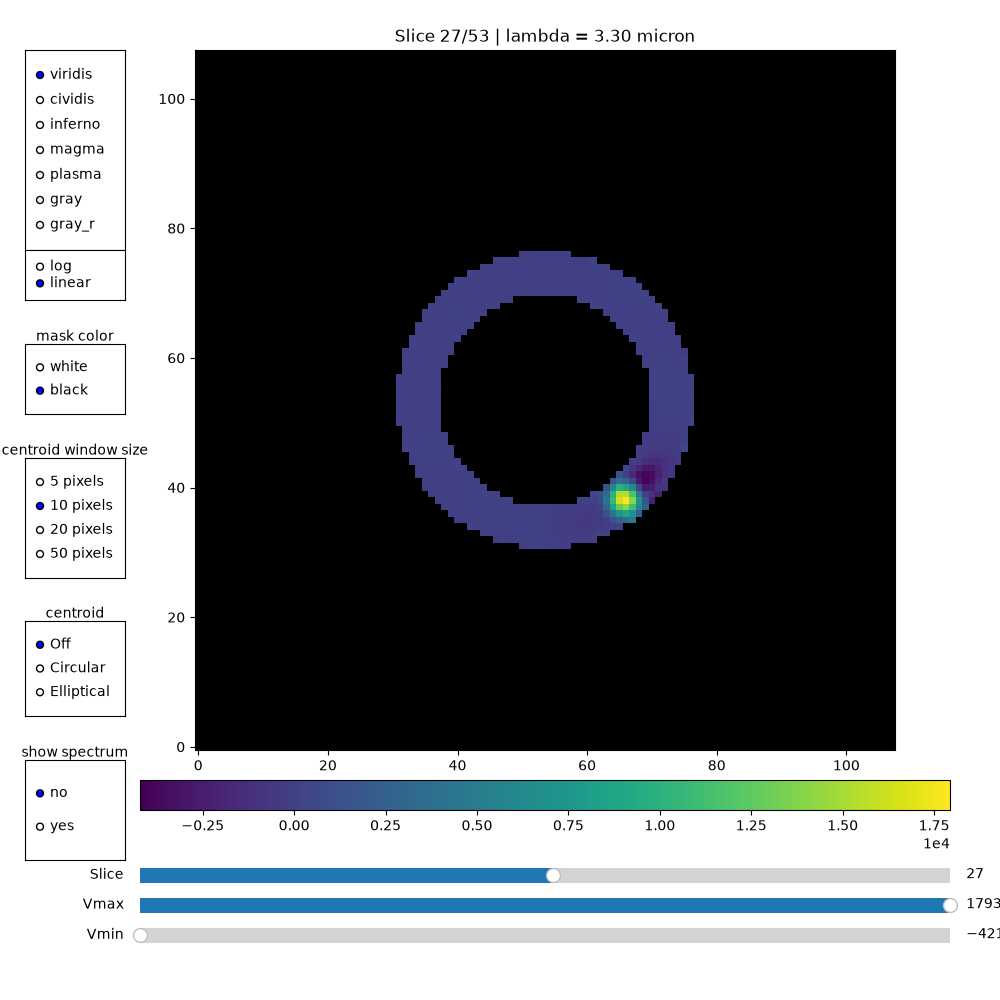

In [9]:
jfits.InteractiveDisplayCube(reduced_cube, wavelengths=WAVELENGTHS,
                             wavelength_unit="micron")

## 8. Combine wavelengths into a detection image

Median-combining the spectral channels beats the noise down further. We also form
a **matched-filtered** view: smoothing by the size of the telescope's PSF
(`lambda / D`) optimally boosts point sources of that size relative to pixel
noise. The green circle marks the injected planet's position.

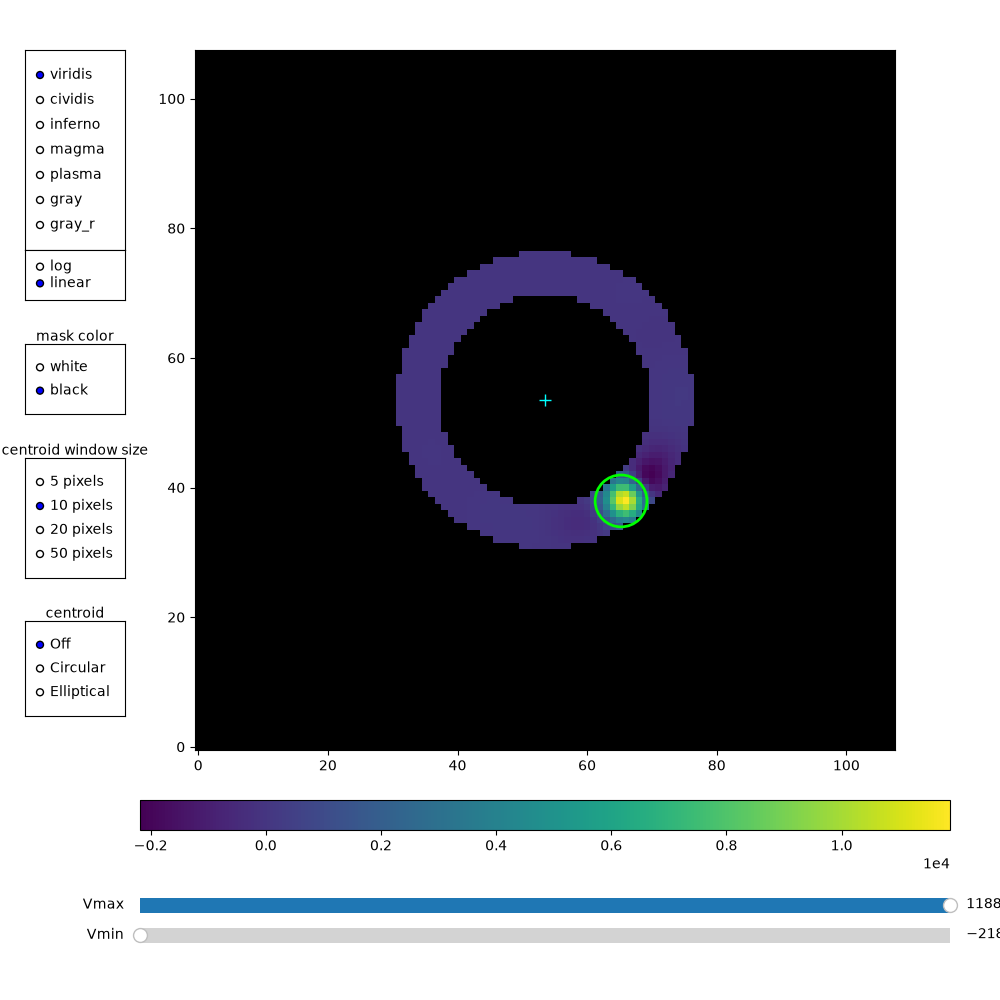

In [10]:
broadband = np.nanmedian(reduced_cube, axis=0)

# matched filter: smooth by roughly the PSF size (lambda / D, in pixels)
lam_over_D_mas = 206_265_000 * (WAVELENGTHS.mean() * 1e-6) / TELESCOPE_DIAMETER
psf_sigma_pix = (lam_over_D_mas / PIXEL_SCALE) / 2.355
matched = gaussian_filter(np.nan_to_num(broadband), psf_sigma_pix)
matched[~np.isfinite(broadband)] = np.nan

display = jfits.InteractiveDisplay(matched)
display.ax.add_patch(plt.Circle((planet_x, planet_y), 4, ec="lime", fc="none", lw=2))
display.ax.plot(*star_center, "+", color="cyan", ms=9)

## 9. Measure the companion's signal-to-noise

`jPhot.get_noise` measures the flux in a resolution-element aperture on the
companion (the signal) and the scatter of the same aperture placed at the other
independent positions around a ring at that separation (the noise); their ratio
is the signal-to-noise. The `filter` argument sets the aperture weighting --
`'tophat'` (uniform), `'gaussian'`, or `'matched'` (weight by a PSF template; see
the closing notes).

In [11]:
signal, noise, n_apertures = jPhot.get_noise(
    broadband, planet_x, planet_y, star_center,
    wavelength=WAVELENGTHS.mean(), D=TELESCOPE_DIAMETER, pixscale=PIXEL_SCALE,
    filter="tophat")
snr = signal / noise

print(f"planet signal (aperture) : {signal:.3g}")
print(f"background noise          : {noise:.3g}  (from {n_apertures} independent apertures)")
print(f"signal-to-noise          : {snr:.1f} sigma")

planet signal (aperture) : 1.39e+05
background noise          : 5.61e+03  (from 35 independent apertures)
signal-to-noise          : 24.8 sigma


## 10. Detection limits

This example ships with the **bright** planet (`pLmag9`) -- an easy,
high-significance detection, and a good way to confirm the geometry (the source
should land right on the circle). The same simulation was generated at fainter
planet brightnesses too:

- **Medium (`pLmag12`)** -- a marginal case; useful for seeing how the
  significance depends on `N_COMPONENTS` and the ring width.
- **Faint (`pLmag14p66`)** -- below the noise floor of this reduction: the planet
  does not rise above the residual speckles at its separation no matter how the
  knobs are tuned. That non-detection is itself the useful result -- it maps the
  contrast limit of these data at this separation.

Those additional cubes are not included in the download, but the reduction runs
on them unchanged if you have them -- just point `DATA_FILE` at the file.

Good things to vary on the bundled data: `N_COMPONENTS` (subtraction
aggressiveness), `ANNULUS_WIDTH`, and the range of wavelengths combined in the
detection image.

## Notes and further reading

- **Building blocks used here:** `jPCA.make_adi_library` (reference selection),
  `jPCA.PCA` (principal-component subtraction; `method='svd'` by default, or a
  faster `method='eigh'` that eigendecomposes the smaller covariance matrix), and
  `nan_rot.nan_rot` (NaN-aware image rotation).
- **Signal-to-noise:** `jPhot.get_noise` supports `filter='tophat'|'gaussian'|'matched'`.
  For `'matched'`, pass a centered PSF stamp as `psf_template`. Because the
  pipeline derotates each frame, the appropriate template is the PSF
  *position-angle-averaged* over the derotation angles -- build it with
  `jPhot.pa_averaged_stamp(psf_stamp, derot_angles)`, using the same angles you
  passed to `nan_rot`. (That captures the field-rotation averaging; the KLIP
  self-subtraction response would require forward-modeling an injected source.)
- **Also in `jighcontrast`:** `jPCA.make_adi_sdi_library` (combined
  angular + spectral reference selection), `jPCA.get_sector_inds` (wedge-shaped
  optimization regions), and `jPhot.PSFAdder` (inject fake planets to calibrate
  throughput).
- **Derotation sign** depends on your rotation routine's convention -- always
  confirm it on a known source, as noted in section 5.